<a href="https://colab.research.google.com/github/davijsf/inteligencia-artificial/blob/main/RBF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Regressao Logistica (sklearn): acc_treino=0.5357  acc_teste=0.4167
w = [0.07253104 0.01377096], b = -0.1433

   k              sigma  valor sigma  acc treino  acc teste
   5      dmax/sqrt(2k)       0.8479      0.9429     0.9167
   5         0.3 (fixo)       0.3000      0.6571     0.5667
   5         0.8 (fixo)       0.8000      0.8857     0.9000
  10      dmax/sqrt(2k)       0.7649      0.9786     1.0000
  10         0.3 (fixo)       0.3000      0.8143     0.7333
  10         0.8 (fixo)       0.8000      0.9929     1.0000
  20      dmax/sqrt(2k)       0.5709      1.0000     1.0000
  20         0.3 (fixo)       0.3000      0.9929     1.0000
  20         0.8 (fixo)       0.8000      1.0000     1.0000
  40      dmax/sqrt(2k)       0.4367      1.0000     0.9833
  40         0.3 (fixo)       0.3000      1.0000     0.9833
  40         0.8 (fixo)       0.8000      1.0000     0.9833

Melhor combinacao: k=10, sigma=0.7649 (dmax/sqrt(2k)), acc_teste=1.0000


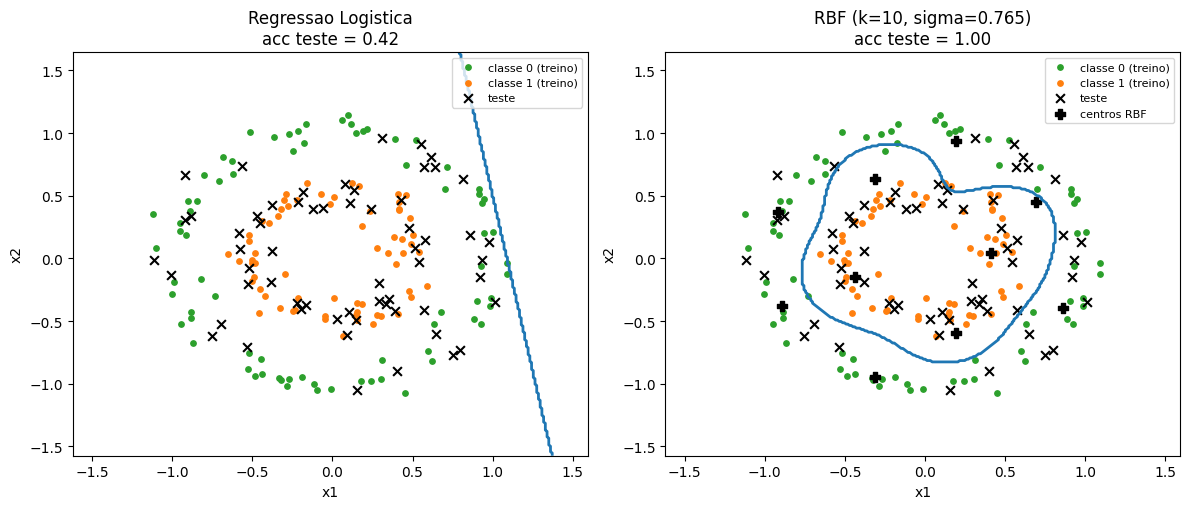

In [4]:
"""
Desafio 11 - RBF em NumPy puro (k-medias + minimos quadrados) vs Regressao Logistica
Problema: make_circles (disco dentro do anel)
"""
import numpy as np
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

rng = np.random.RandomState(42)

# ---------------------------------------------------------------
# 1. Dados: disco dentro do anel
# ---------------------------------------------------------------
X, y = make_circles(n_samples=200, noise=0.08, factor=0.5, random_state=42)
# make_circles: classe 0 = anel externo, classe 1 = disco interno (com factor<1)

n = X.shape[0]
idx = rng.permutation(n)
n_train = int(0.7 * n)
train_idx, test_idx = idx[:n_train], idx[n_train:]

X_train_raw, X_test_raw = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# padronizacao usando so as estatisticas do treino
mu = X_train_raw.mean(axis=0)
sd = X_train_raw.std(axis=0)
X_train = (X_train_raw - mu) / sd
X_test = (X_test_raw - mu) / sd

# ---------------------------------------------------------------
# 2. K-medias do zero (so nas entradas, sem rotulos)
# ---------------------------------------------------------------
def kmeans(X, k, n_iter=200, n_init=10, seed=0):
    best_inertia = np.inf
    best_centers = None
    rs = np.random.RandomState(seed)
    for init in range(n_init):
        # inicializacao: k pontos aleatorios dos dados (sem repeticao)
        centers = X[rs.choice(X.shape[0], size=k, replace=False)].copy()
        for _ in range(n_iter):
            # atribuir cada ponto ao centro mais proximo
            d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
            labels = d2.argmin(axis=1)
            new_centers = centers.copy()
            for j in range(k):
                mask = labels == j
                if mask.sum() > 0:
                    new_centers[j] = X[mask].mean(axis=0)
                # se um centro ficar sem pontos, mantem o antigo
            if np.allclose(new_centers, centers):
                centers = new_centers
                break
            centers = new_centers
        d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = d2.argmin(axis=1)
        inertia = d2[np.arange(X.shape[0]), labels].sum()
        if inertia < best_inertia:
            best_inertia = inertia
            best_centers = centers
    return best_centers

# ---------------------------------------------------------------
# 3. Camada RBF: phi_j(x) = exp(-||x-c_j||^2 / sigma^2)
# ---------------------------------------------------------------
def rbf_features(X, centers, sigma):
    d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    Phi = np.exp(-d2 / (sigma ** 2))
    # adiciona coluna de 1s (vies)
    return np.hstack([Phi, np.ones((X.shape[0], 1))])

def dmax_centers(centers):
    d = ((centers[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2) ** 0.5
    return d.max()

def train_rbf(X_train, y_train, X_test, y_test, k, sigma, seed=0):
    centers = kmeans(X_train, k, seed=seed)
    H_train = rbf_features(X_train, centers, sigma)
    H_test = rbf_features(X_test, centers, sigma)
    # minimos quadrados via pseudoinversa
    beta = np.linalg.pinv(H_train) @ y_train
    f_train = H_train @ beta
    f_test = H_test @ beta
    acc_train = accuracy_score(y_train, (f_train >= 0.5).astype(int))
    acc_test = accuracy_score(y_test, (f_test >= 0.5).astype(int))
    return acc_train, acc_test, centers, beta

# ---------------------------------------------------------------
# 4. Baseline: Regressao Logistica (sklearn)
# ---------------------------------------------------------------
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
acc_train_lr = accuracy_score(y_train, logreg.predict(X_train))
acc_test_lr = accuracy_score(y_test, logreg.predict(X_test))

# ---------------------------------------------------------------
# 5. Varredura k x sigma
# ---------------------------------------------------------------
ks = [5, 10, 20, 40]
results = []
best = {"acc_test": -1}

for k in ks:
    centers_tmp = kmeans(X_train, k, seed=1)
    dmax = dmax_centers(centers_tmp)
    sigma_formula = dmax / np.sqrt(2 * k)
    sigmas = {
        "dmax/sqrt(2k)": sigma_formula,
        "0.3 (fixo)": 0.3,
        "0.8 (fixo)": 0.8,
    }
    for sigma_label, sigma in sigmas.items():
        acc_train, acc_test, centers, beta = train_rbf(
            X_train, y_train, X_test, y_test, k, sigma, seed=1
        )
        results.append({
            "k": k,
            "sigma_label": sigma_label,
            "sigma": sigma,
            "acc_train": acc_train,
            "acc_test": acc_test,
        })
        if acc_test > best["acc_test"]:
            best = {"k": k, "sigma": sigma, "sigma_label": sigma_label,
                     "acc_test": acc_test, "centers": centers, "beta": beta}

# ---------------------------------------------------------------
# 6. Impressao da tabela
# ---------------------------------------------------------------
print(f"Regressao Logistica (sklearn): acc_treino={acc_train_lr:.4f}  acc_teste={acc_test_lr:.4f}")
print(f"w = {logreg.coef_[0]}, b = {logreg.intercept_[0]:.4f}")
print()
print(f"{'k':>4} {'sigma':>18} {'valor sigma':>12} {'acc treino':>11} {'acc teste':>10}")
for r in results:
    print(f"{r['k']:>4} {r['sigma_label']:>18} {r['sigma']:>12.4f} {r['acc_train']:>11.4f} {r['acc_test']:>10.4f}")

print()
print(f"Melhor combinacao: k={best['k']}, sigma={best['sigma']:.4f} ({best['sigma_label']}), acc_teste={best['acc_test']:.4f}")

# ---------------------------------------------------------------
# 7. Grafico da fronteira (melhor RBF) + fronteira da RL
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
    np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300),
)
grid_raw = np.c_[xx.ravel(), yy.ravel()]
grid_std = (grid_raw - mu) / sd

# --- painel 1: Regressao Logistica ---
ax = axes[0]
Z_lr = logreg.predict(grid_std).reshape(xx.shape)
ax.contour(xx, yy, Z_lr, levels=[0.5], colors="tab:blue", linewidths=2)
ax.scatter(X_train_raw[y_train == 0, 0], X_train_raw[y_train == 0, 1],
           c="tab:green", s=15, label="classe 0 (treino)")
ax.scatter(X_train_raw[y_train == 1, 0], X_train_raw[y_train == 1, 1],
           c="tab:orange", s=15, label="classe 1 (treino)")
ax.scatter(X_test_raw[:, 0], X_test_raw[:, 1], color="black",
           s=40, marker="x", label="teste")
ax.set_title(f"Regressao Logistica\nacc teste = {acc_test_lr:.2f}")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(fontsize=8, loc="upper right")

# --- painel 2: melhor RBF ---
ax = axes[1]
H_grid = rbf_features(grid_std, best["centers"], best["sigma"])
Z_rbf = (H_grid @ best["beta"] >= 0.5).astype(int).reshape(xx.shape)
ax.contour(xx, yy, Z_rbf.astype(float), levels=[0.5], colors="tab:blue", linewidths=2)
ax.scatter(X_train_raw[y_train == 0, 0], X_train_raw[y_train == 0, 1],
           c="tab:green", s=15, label="classe 0 (treino)")
ax.scatter(X_train_raw[y_train == 1, 0], X_train_raw[y_train == 1, 1],
           c="tab:orange", s=15, label="classe 1 (treino)")
ax.scatter(X_test_raw[:, 0], X_test_raw[:, 1], color="black",
           s=40, marker="x", label="teste")
centers_raw = best["centers"] * sd + mu
ax.scatter(centers_raw[:, 0], centers_raw[:, 1], c="black", s=60, marker="P",
           label="centros RBF")
ax.set_title(f"RBF (k={best['k']}, sigma={best['sigma']:.3f})\nacc teste = {best['acc_test']:.2f}")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(fontsize=8, loc="upper right")

plt.tight_layout()